# ニューラル N-gram 言語モデルの学習

[Bengio ら（2003）](https://papers.nips.cc/paper_files/paper/2000/hash/728f206c2a01bf572b5940d7d9a8fa4c-Abstract.html)の構造をもとにしたニューラル N-gram 言語モデルの実装です。PyTorch を使い、青空文庫のテキストで学習します。

In [1]:
!pip install -q torch  # ニューラルネットワークの実装と学習
!pip install -q datasets  # 青空文庫コーパスの取得（Hugging Face）
!pip install -q fugashi  # 日本語の単語分割（形態素解析）
!pip install -q unidic-lite  # fugashi が使う軽量な辞書
!pip install -q matplotlib  # 学習曲線の描画
!pip install -q japanize-matplotlib  # matplotlib のグラフを日本語表示にする

## データを用意する

学習には青空文庫の作品を用います。筆者が前処理を施したデータを Hugging Face の `datasets` から取得します。

テキストを `fugashi` というライブラリを通して単語に分割します。

In [2]:
import fugashi
from datasets import load_dataset

# 各作品から取り出す文字数
chars_per_work = 10000

dataset = load_dataset("ryo0634/aozora-bunko-modern-only", split="train")

tagger = fugashi.Tagger()


def tokenize(text: str) -> list[str]:
    """テキストを単語（表層形）のリストに分割する。"""
    return [token.surface for token in tagger(text)]


# 各作品ごとに独立してトークナイズした単語リストを保持する（all_words_flat はグローバルで保持しない）
works_words = []
for item in dataset:
    text_segment = item["text"].strip()[:chars_per_work]
    work_tokens = tokenize(text_segment)
    works_words.append(work_tokens)

print(f"収集した作品数: {len(works_words)}")
print("1つ目の作品の先頭単語:", works_words[0][:15] if works_words else [])

収集した作品数: 8036
1つ目の作品の先頭単語: ['橋', 'の', '袂', 'に', '美女', 'の', '裸身', '\u3000', 'し', 'はん', 'ほ', 'に', 'なす', 'はか', 'は']


先頭を見ると、助詞や句読点も1つの単語として切り出されています。表示された単語列が、このあとの学習データのもとになります。

## 語彙をつくる

出力層は語彙中の全単語について確率を出すため、語彙が大きいほど計算が重くなります。そこで文頭 `<bos>` と未知語 `<unk>` 用の2枠を除き、頻度の高い上位 `max_vocab - 2` 語だけを残し、それ以外の珍しい単語はすべて未知語 `<unk>` にまとめます。

語彙（単語 ID の相互変換）は `Vocab` にまとめ、`encode`（単語 → ID）と `decode`（ID → 単語）で行き来します。この対応表を使って、テキストの単語をモデルに渡す整数へ変換します。

`@dataclass` は、列挙したデータを受け取る初期化処理を自動で作る Python 標準の仕組みです。ここでは単語と ID の対応表をまとめます。

In [3]:
from collections import Counter
from dataclasses import dataclass

# 特殊トークンの定義
BOS = "<bos>"  # 文頭用（ID: 0）
UNK = "<unk>"  # 未知語用（ID: 1）

@dataclass
class Vocab:
    """特殊トークン（<bos>, <unk>）に対応したシンプルな語彙。"""
    id_to_word: list[str]
    word_to_id: dict[str, int]

    @property
    def size(self) -> int:
        return len(self.id_to_word)

    def encode(self, words: list[str]) -> list[int]:
        # 語彙にない単語はすべて UNK トラクンの ID にマッピングします
        unk_id = self.word_to_id[UNK]
        return [self.word_to_id.get(w, unk_id) for w in words]

    def decode(self, ids: list[int]) -> list[str]:
        return [self.id_to_word[i] for i in ids]


def build_vocab_with_specials(works_words: list[list[str]], max_vocab: int = 4000) -> Vocab:
    """特殊トークン <bos>, <unk> を先頭に固定したうえで語彙を構築する。"""
    counter = Counter()
    for work in works_words:
        counter.update(work)

    specials = [BOS, UNK]
    common = [w for w, _ in counter.most_common(max_vocab - len(specials))]

    id_to_word = specials + common
    word_to_id = {w: i for i, w in enumerate(id_to_word)}
    return Vocab(id_to_word=id_to_word, word_to_id=word_to_id)

# 語彙の再構築
vocab = build_vocab_with_specials(works_words, max_vocab=16000)

print(f"語彙サイズ: {vocab.size:,}")

語彙サイズ: 16,000


表示された語彙サイズには、文頭 `<bos>` と未知語 `<unk>` も含まれます。ここでは `max_vocab=16000` とし、語彙にない単語は `<unk>` の ID に変換します。

## 学習データ（文脈 → 次単語）をつくる

ニューラル N-gram 言語モデルは、直前 $N-1$ 単語の文脈から次の1単語を予測します。ここでは $N=5$、つまり文脈 `context_size = 4` 単語とします。各作品の単語 ID 列の上を幅 $N$ の窓でずらしながら、(文脈4単語, 次単語) の組を大量に切り出します。PyTorch の `Tensor` は数値を並べた配列です。下の `context_tensors` は「サンプル数 × 文脈長」、`target_tensors` は「サンプル数」の形になります。

In [4]:
import torch

context_size = 4  # N-1

all_contexts = []
all_targets = []

# 各作品ごとに個別に単語 ID 化し、N-gram の窓を適用してスライスする
for work_tokens in works_words:
    if len(work_tokens) <= context_size:
        continue
    id_seq = torch.tensor(vocab.encode(work_tokens), dtype=torch.long)
    windows = id_seq.unfold(0, context_size + 1, 1)

    work_contexts = windows[:, :context_size]
    work_targets = windows[:, context_size]

    all_contexts.append(work_contexts)
    all_targets.append(work_targets)

# 作品間で混ざらないように個別スライスしたものを最後に1つのテンソルに結合する
context_tensors = torch.cat(all_contexts, dim=0).contiguous()
target_tensors = torch.cat(all_targets, dim=0).contiguous()

# シャッフルや時系列の分割を行う
n_train = int(0.9 * len(context_tensors))
train_data = (context_tensors[:n_train], target_tensors[:n_train])
val_data = (context_tensors[n_train:], target_tensors[n_train:])

print(f"学習サンプル数: {len(train_data[0]):,}")
print(f"検証サンプル数: {len(val_data[0]):,}")
example_context = vocab.decode(context_tensors[0].tolist())
print(f"例: 「{example_context}」 → 「{vocab.id_to_word[target_tensors[0].item()]}」")

学習サンプル数: 26,157,368
検証サンプル数: 2,906,375
例: 「['橋', 'の', '袂', 'に']」 → 「美女」


### 補足：Dataset を使ったデータ読み出し

別の書き方として、作品ごとの単語 ID 列と、各サンプルの位置（作品 ID と作品内の開始位置）を保持する `NgramDataset` を定義します。サンプルが必要になったときに、その位置から文脈と次単語を切り出します。

この補足ではサンプルをランダムに学習用・検証用へ分け、`DataLoader` から1バッチ取り出します。後半のモデル学習では、先ほどテンソルから作った `train_data` と `val_data` を使います。ここで作る `train_subset` と `val_subset` は、読み出し方の例を示すためのものです。

In [5]:
from torch.utils.data import Dataset, DataLoader

class NgramDataset(Dataset):
    """メモリ消費を抑え、作品の境界を跨がないように動的に N-gram を切り出す Dataset。"""
    def __init__(self, works_words: list[list[str]], vocab: Vocab, context_size: int) -> None:
        self.context_size = context_size
        # 各作品の単語 ID リストをテンソルとして個別に保持（複製なし）
        self.works_ids = [torch.tensor(vocab.encode(work), dtype=torch.long) for work in works_words]

        # 各サンプルの「(作品インデックス, その作品内での開始位置)」をマッピングとして構築
        self.samples = []
        for work_idx, ids in enumerate(self.works_ids):
            n_tokens = len(ids)
            if n_tokens > context_size:
                # N-gram（文脈 + ターゲット）が切り出せる位置の数
                n_samples = n_tokens - context_size
                for start_pos in range(n_samples):
                    self.samples.append((work_idx, start_pos))

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor]:
        work_idx, start_pos = self.samples[idx]
        work_ids = self.works_ids[work_idx]

        # 呼び出し時にその場でスライスして返す
        context = work_ids[start_pos : start_pos + self.context_size]
        target = work_ids[start_pos + self.context_size]
        return context, target

# データセットの作成
efficient_dataset = NgramDataset(works_words, vocab, context_size)

# 訓練・検証用の分割（インデックスベースでのサブセット作成）
total_size = len(efficient_dataset)
n_train = int(0.9 * total_size)
train_subset, val_subset = torch.utils.data.random_split(
    efficient_dataset,
    [n_train, total_size - n_train],
    generator=torch.Generator().manual_seed(42)
)

print(f"総サンプル数 (メモリ効率化版): {total_size:,}")
print(f"学習用: {len(train_subset):,}, 検証用: {len(val_subset):,}")

# DataLoader もこれを使って最小限のメモリでバッチ作成が可能です
test_loader = DataLoader(train_subset, batch_size=5, shuffle=True)
for batch_x, batch_y in test_loader:
    print("バッチ入力の形状:", batch_x.shape) # (batch_size, context_size)
    print("バッチターゲットの形状:", batch_y.shape) # (batch_size,)
    break

総サンプル数 (メモリ効率化版): 29,063,743
学習用: 26,157,368, 検証用: 2,906,375
バッチ入力の形状: torch.Size([5, 4])
バッチターゲットの形状: torch.Size([5])


文脈4単語とその次単語の組が、1つの学習例です。後半の学習に使う `train_data` と `val_data` は、作品ごとに切り出して連結したテンソルの先頭約9割と、残りの約1割です。この予測を大量に解かせることで、モデルは「どんな文脈の後にどんな単語が来やすいか」を学びます。

## モデルを定義する

単語 ID を受け取って次単語のスコアを出す計算を、入力側から順に組み立てます。

1. **埋め込み層**：各単語 ID をベクトルに変換します。同じ単語には、文脈中の位置によらず同じベクトルを使います。
2. **連結**：文脈の $N-1$ 個の単語ベクトルをつないで、入力ベクトル $\mathbf{x}$ にします。
3. **隠れ層**：$\mathbf{h}=\tanh(\mathbf{d}+\mathbf{H}\mathbf{x})$ を計算します。
4. **出力層**：隠れ層からのスコアと、入力から直接計算したスコアを足します。

$$\mathbf{y}=\mathbf{b}+\mathbf{W}\mathbf{x}+\mathbf{U}\tanh(\mathbf{d}+\mathbf{H}\mathbf{x})$$

入力からの線形な関係を学ぶ経路 $\mathbf{W}\mathbf{x}$ と、tanh を通じて非線形な関係を学ぶ経路を併用します。

In [6]:
import torch
import torch.nn as nn


class NeuralNgramLM(nn.Module):
    """Bengio らのオリジナル論文に準拠したニューラル N-gram 言語モデル。
    埋め込みを連結した入力から出力への直接接続（ダイレクト接続）を持ちます。
    """

    def __init__(
        self, vocab_size: int, context_size: int, embed_dim: int, hidden_dim: int
    ) -> None:
        super().__init__()
        self.context_size = context_size
        self.embedding = nn.Embedding(vocab_size, embed_dim)  # 埋め込み行列 E
        self.hidden = nn.Linear(embed_dim * context_size, hidden_dim)
        self.output = nn.Linear(hidden_dim, vocab_size)  # U と出力バイアス b
        self.direct = nn.Linear(embed_dim * context_size, vocab_size, bias=False)  # W

    def forward(self, context: torch.Tensor) -> torch.Tensor:
        # context: (batch, context_size) の単語 ID
        e = self.embedding(context)  # 各単語の埋め込み e_i
        x = e.view(e.size(0), -1)  # 連結して入力ベクトル x
        h = torch.tanh(self.hidden(x))  # 隠れ層 + Tanh
        y = self.output(h) + self.direct(x)  # b + U h + W x（Softmax 前）
        return y


In [7]:
torch.manual_seed(42) # ランダムシードを固定して、結果を再現しやすくする

sanity_model = NeuralNgramLM(vocab.size, context_size, embed_dim=64, hidden_dim=128)
sample_logits = sanity_model(context_tensors[:4])
print(f"パラメータ数: {sum(p.numel() for p in sanity_model.parameters()):,}")
print(f"入力 {tuple(context_tensors[:4].shape)} → 出力 {tuple(sample_logits.shape)}")

パラメータ数: 7,216,896
入力 (4, 4) → 出力 (4, 16000)


入力（4サンプル × 文脈4単語）が、語彙サイズ $|V|$ 次元の出力に変換されました。この $|V|$ 個の値に Softmax をかけると次単語の確率分布になります。まだ学習していないので、いまの確率はほぼランダムです。

## 学習ループを用意する

学習は `train` 関数にまとめます。関数に渡したモデルのパラメータを更新し、エポックごとの損失を `history` として返します。各エポックでは、データをシャッフルして小分け（ミニバッチ）にし、ミニバッチごとにパラメータを更新します。

損失には `nn.CrossEntropyLoss` を使います。これは Softmax（$\mathbf{p}$）と交差エントロピー（$L = -\log p_{w_t}$）を内部でまとめて計算してくれるので、出力 $\mathbf{y}$（logits）をそのまま渡します。交差エントロピーは、正解の次単語の予測確率 $p_{w_t}$ が高いほど小さくなる損失です。`loss.backward()` で勾配を計算し、`optimizer.step()` でパラメータを更新します。検証用データでは更新せず、未知のデータへの予測を調べます。

In [8]:
from tqdm.notebook import tqdm
import torch
import torch.nn as nn

# GPU が利用可能か自動検出
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用中のデバイス: {device}")


def evaluate(
    model: nn.Module,
    context_tensors: torch.Tensor,
    target_tensors: torch.Tensor,
    criterion: nn.Module,
    batch_size: int = 4096,  # 評価時はバッチサイズを大きくして高速化
) -> float:
    """勾配を計算せずに平均損失を求める（GPU対応）。"""
    model.eval()
    total, n = 0.0, 0
    # 評価用データをあらかじめ GPU に送ることで高速化
    context_gpu = context_tensors.to(device)
    target_gpu = target_tensors.to(device)

    with torch.no_grad():
        for start in range(0, len(context_gpu), batch_size):
            batch_x = context_gpu[start : start + batch_size]
            batch_y = target_gpu[start : start + batch_size]

            # 自動混合精度 (AMP) を使用して高速化
            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                logits = model(batch_x)
                loss = criterion(logits, batch_y)

            total += loss.item() * len(batch_y)
            n += len(batch_y)
    return total / n


def train(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    train_data: tuple[torch.Tensor, torch.Tensor],
    val_data: tuple[torch.Tensor, torch.Tensor],
    n_epochs: int = 8,
    batch_size: int = 4096,  # GPU 向けにバッチサイズを大きく（512 -> 4096）して並列性能を解放
    seed: int = 42,
) -> dict[str, list[float]]:
    """モデルをミニバッチ学習し、エポックごとの訓練/検証損失の履歴を返す。
    """
    model.to(device)  # モデルを GPU へ転送
    train_x, train_y = train_data

    # データをあらかじめ GPU に載せることで、毎ステップの転送オーバーヘッドをゼロに（メモリに余裕がある場合に推奨）
    train_x_gpu = train_x.to(device)
    train_y_gpu = train_y.to(device)

    criterion = nn.CrossEntropyLoss()

    # 自動混合精度を使用する場合に、アンダーフローを防ぐ仕組み
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

    history: dict[str, list[float]] = {"train": [], "val": []}
    generator = torch.Generator(device=device).manual_seed(seed)

    for epoch in range(n_epochs):
        model.train()
        order = torch.randperm(
            len(train_x_gpu), generator=generator, device=device
        )  # シャッフルしてデータを読み出すための配列

        total, n_samples = 0.0, 0
        steps = range(0, len(train_x_gpu), batch_size)
        progress_bar = tqdm(steps, desc=f"Epoch {epoch + 1}/{n_epochs}", leave=False)

        for start in progress_bar:
            idx = order[start : start + batch_size]
            batch_x = train_x_gpu[idx]
            batch_y = train_y_gpu[idx]

            optimizer.zero_grad(set_to_none=True)  # zero_grad(set_to_none=True) でメモリ効率化

            # 自動混合精度 (AMP) を使用してフォワードパスを実行
            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                logits = model(batch_x)
                loss = criterion(logits, batch_y)

            # スケーラーを使用してバックプロパゲーションと更新
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_size_actual = len(idx)
            total += loss.item() * batch_size_actual
            n_samples += batch_size_actual

            progress_bar.set_postfix(loss=f"{loss.item():.4f}")

        train_loss = total / n_samples
        val_loss = evaluate(model, val_data[0], val_data[1], criterion)

        history["train"].append(train_loss)
        history["val"].append(val_loss)

        print(
            f"Epoch {epoch + 1:2d}/{n_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f}"
        )

    return history

使用中のデバイス: cuda


## 学習する

最適化には Adam を使います。学習損失（train）と検証損失（val）の推移を比べます。学習損失が下がっても検証損失が下がらない場合は、学習データへの当てはまりだけがよくなっている可能性があります。

In [9]:
torch.manual_seed(42)
model = NeuralNgramLM(vocab.size, context_size, embed_dim=64, hidden_dim=128)
untrained_embedding = model.embedding.weight.detach().clone()  # 学習前の値を保存する
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history = train(model, optimizer, train_data, val_data, n_epochs=5, batch_size=512)

/tmp/ipykernel_27507/2888321119.py:60: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


Epoch 1/5:   0%|          | 0/51089 [00:00<?, ?it/s]

/tmp/ipykernel_27507/2888321119.py:83: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
/tmp/ipykernel_27507/2888321119.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


Epoch  1/5 - train_loss: 4.3384 - val_loss: 4.1952


Epoch 2/5:   0%|          | 0/51089 [00:00<?, ?it/s]

...

Epoch  3/5 - train_loss: 4.0382 - val_loss: 4.1039


Epoch 4/5:   0%|          | 0/51089 [00:00<?, ?it/s]

Epoch  4/5 - train_loss: 4.0027 - val_loss: 4.0907


Epoch 5/5:   0%|          | 0/51089 [00:00<?, ?it/s]

Epoch  5/5 - train_loss: 3.9798 - val_loss: 4.0834


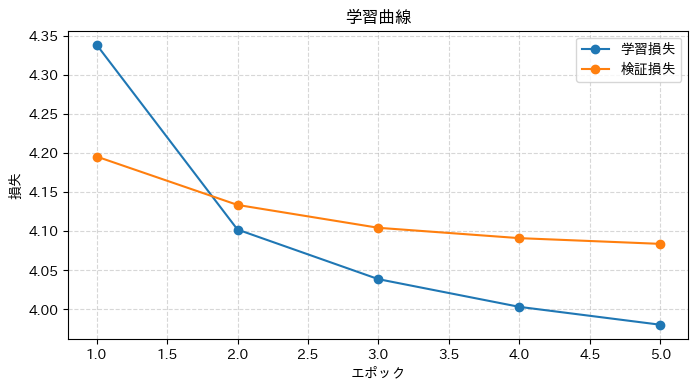

In [10]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # import するだけで図の日本語表示が有効になる

plt.figure(figsize=(8, 4))
epochs = range(1, len(history["train"]) + 1)
plt.plot(epochs, history["train"], marker="o", label="学習損失")
plt.plot(epochs, history["val"], marker="o", label="検証損失")
plt.xlabel("エポック")
plt.ylabel("損失")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.title("学習曲線")
plt.show()

学習損失が下がれば、学習データの次単語に高い確率を与えられるようになっています。検証損失も下がるか、途中で下げ止まるかを曲線で確認してください。検証損失の改善が、学習に使っていない例への予測がよくなる目安です。

## テキストを生成する

学習したモデルで文章を生成します。プロンプト（書き出し）の単語列を入力し、出力した確率分布から次の単語をサンプリングして、それを文脈に加えることを繰り返す自己回帰生成です。`temperature` は分布の鋭さを調整する温度で、小さいほど確率の高い単語を選びがちになります。

文脈が4単語に満たないときは、先頭に文頭トークン `<bos>` を補います。生成時には `<unk>` と `<bos>` を候補から外し、表示時にも `<bos>` を取り除きます。

以下では同じ名前の `generate_text` を続けて定義しているため、上から実行すると後の定義を使います。後の定義では、先頭に補ったパディングの長さを記録してから取り除きます。

In [11]:
def generate_text(
    model: NeuralNgramLM,
    vocab: Vocab,
    prompt: str,
    n_new: int = 40,
    temperature: float = 0.8,
    seed: int = 42,
) -> str:
    """プロンプトに続けて単語を自己回帰的に生成する。
    文脈長に満たない部分は、文頭を表す <bos> で埋めます。
    """
    model.eval()
    size = model.context_size

    # 入力をトークナイズしてID化
    tokens = tokenize(prompt)
    ids = vocab.encode(tokens)

    # 文脈長（N-1）に満たないとき、先頭を <bos> トークン（ID: 0）でパディングする
    bos_id = vocab.word_to_id[BOS]
    if len(ids) < size:
        ids = [bos_id] * (size - len(ids)) + ids

    generated = list(ids)
    generator = torch.Generator().manual_seed(seed)
    device = next(model.parameters()).device

    with torch.no_grad():
        for _ in range(n_new):
            x = torch.tensor([generated[-size:]], dtype=torch.long, device=device)
            probs = torch.softmax(model(x)[0] / temperature, dim=0)

            # <unk> や <bos> などの特殊トークンが予測の直後に選ばれないように確率をゼロにする
            probs[vocab.word_to_id[UNK]] = 0.0
            probs[vocab.word_to_id[BOS]] = 0.0

            next_id = torch.multinomial(probs.cpu(), 1, generator=generator).item()
            generated.append(next_id)

    # デコードの際、特殊トークン <bos> は画面に表示しないようにフィルタリングする
    decoded_tokens = [vocab.id_to_word[idx] for idx in generated if vocab.id_to_word[idx] != BOS]
    return "".join(decoded_tokens)

In [27]:
def generate_text(
    model: NeuralNgramLM,
    vocab: Vocab,
    prompt: str,
    n_new: int = 40,
    temperature: float = 0.8,
    seed: int = 42,
) -> str:
    """プロンプトに続けて単語を自己回帰的に生成する。
    文脈長に満たない部分は、文頭を表す <bos>（存在しない場合は安全な代替）で埋めます。
    """
    model.eval()
    size = model.context_size

    # 入力をトークナイズしてID化
    ids = vocab.encode(tokenize(prompt))

    # <bos> をパディングに用いる
    bos_id = vocab.word_to_id[BOS]
    pad_token_str = BOS

    # パディングされた位置（生成ループに入る前のパディングトークンの個数）を記録しておく
    pad_len = 0
    if len(ids) < size:
        pad_len = size - len(ids)
        ids = [bos_id] * pad_len + ids

    generated = list(ids)
    generator = torch.Generator().manual_seed(seed)
    device = next(model.parameters()).device

    # <unk> トークンの ID を取得
    unk_id = vocab.word_to_id.get("<unk>", 0)

    with torch.no_grad():
        for _ in range(n_new):
            x = torch.tensor([generated[-size:]], dtype=torch.long, device=device)
            probs = torch.softmax(model(x)[0] / temperature, dim=0)

            # 特殊トークンが予測の直後に選ばれないように確率をゼロにする
            if unk_id < len(probs):
                probs[unk_id] = 0.0
            if BOS in vocab.word_to_id:
                probs[vocab.word_to_id[BOS]] = 0.0

            next_id = torch.multinomial(probs.cpu(), 1, generator=generator).item()
            generated.append(next_id)

    # 先頭に埋めたパディング部分を取り除き、残りをデコードする
    unpadded_generated = generated[pad_len:]
    decoded_tokens = [vocab.id_to_word[idx] for idx in unpadded_generated if vocab.id_to_word[idx] != BOS]
    return "".join(decoded_tokens)

In [28]:
seed = 42
for i, prompt in enumerate(["", "吾輩は"]):
    # プロンプトごとに乱数の種を変える
    print(generate_text(model, vocab, prompt, n_new=40, seed=seed + i))
    print("-" * 40)

其吹いているが、別に変化しても、その地上の一つの十五枚の着物が、二階へ入って、あのように、今度はお綾
----------------------------------------
吾輩は倒れざり顔の声の中からとりも直さず、社会的の画性を測ることができるならば、それが、この方面に関を出さぬ度に、やっ
----------------------------------------


局所的にはそれらしい単語のつながりが出てきますが、内容として意味の通った文にはなかなかなりません。文脈をわずか4単語しか見ていないニューラル N-gram の限界です。

それでも、頻度をそのまま数える古典的な N-gram と違い、埋め込みを介して**学習時に見ていない文脈にも確率を割り当てられる**ため、生成が途切れません。観測した文脈だけではデータが足りない問題（データスパースネス）が、ここでは緩和されています。


## 単語埋め込みを調べる

学習後の埋め込み行列 $\mathbf{E}$ を取り出し、ある単語のベクトルにコサイン類似度が高い（＝近い）単語を観察しましょう。次単語予測の学習によって、似た文脈に現れる単語のベクトルが近くなることを期待します。この小さなコーパスでもその傾向が見えるでしょうか。

コサイン類似度はベクトルの向きの近さを表し、1に近いほど同じ向きです。近い単語を求める処理と、結果を表示する処理を別の関数にします。

In [36]:
def nearest_words(
    embedding: torch.Tensor,
    vocab: Vocab,
    word: str,
    top_k: int = 8,
) -> list[tuple[str, float]]:
    """単語の埋め込みに近い単語を top_k 件返す。"""
    idx = vocab.word_to_id[word]
    sims = torch.cosine_similarity(
        embedding[idx].unsqueeze(0), embedding, dim=1
    )
    order = [i.item() for i in sims.argsort(descending=True) if i.item() != idx]
    return [(vocab.id_to_word[i], sims[i].item()) for i in order[:top_k]]


def compare_neighbors(
    embeddings: torch.Tensor, vocab: Vocab, words: list[str]
) -> None:
    """学習前と学習後の近傍語を、単語ごとに並べて表示する。"""
    for word in words:
        if word not in vocab.word_to_id:
            print(f"「{word}」は語彙にありません")
            continue
        print(f"「{word}」")
        pairs = nearest_words(embeddings, vocab, word)
        print("  ".join(f"{w}({s:.2f})" for w, s in pairs))

In [39]:
embedding = model.embedding.weight.detach()
compare_neighbors(embedding, vocab, ["女", "二", "一", "男", "人"])

「女」
男(0.85)  女性(0.60)  細君(0.57)  人間(0.56)  少女(0.56)  青年(0.56)  婦(0.54)  女子(0.53)
「二」
三(0.72)  四(0.72)  五(0.67)  六(0.62)  七(0.60)  一(0.59)  八(0.55)  五六(0.50)
「一」
二(0.59)  ひと(0.57)  二三(0.57)  一二(0.55)  一、二(0.52)  〇(0.52)  三(0.51)  五(0.50)
「男」
女(0.85)  娘(0.61)  若者(0.59)  人(0.58)  老人(0.56)  青年(0.55)  少女(0.54)  女性(0.54)
「人」
者(0.78)  員(0.60)  男(0.58)  村人(0.57)  人数(0.57)  船員(0.57)  客(0.56)  若者(0.56)


人を表す単語の近くには、同様に人を表す単語が集まり、数字の近くには数字が集まっていることが観察できます。

## まとめ

- Bengio 型ニューラル N-gram 言語モデル（埋め込み → 連結 → Tanh → Softmax）を PyTorch で実装し、青空文庫で学習させました。
- エポックごとに損失が下がり、モデルが次単語予測を学んでいく様子を確認しました。
- 埋め込みを介することで、学習時に見ていない文脈にも確率を割り当てられ、生成が途切れません。観測した文脈だけではデータが足りない問題が緩和されています。
- 学習後の埋め込みの近傍語を表示し、意味や用法が近い単語が集まるかを観察しました。

## 実験してみよう

1. **文脈長を変える**：`context_size` を 2 や 5 にすると、生成文の自然さや損失はどう変わるでしょうか。
2. **埋め込み次元を変える**：`embed_dim` を 16 や 128 にすると、学習損失や近傍語の傾向はどう変わるでしょうか。
